#Prezentarea setului de date Human Activity Recognition with Smartphones


Setul de date ales este Human Activity Recognition Using Smartphones (HAR). Acesta a fost creat în cadrul University of California și conține informații colectate de la 30 de voluntari care au efectuat șase activități cotidiene: mers, urcat scări, coborât scări, șezut, stat în picioare și culcat.

Datele au fost înregistrate cu ajutorul senzorilor de accelerometru și giroscop integrați într-un smartphone purtat la nivelul taliei. Semnalele brute au fost eșantionate la o frecvență de 50 Hz și ulterior împărțite în ferestre temporale de aproximativ 2,56 secunde, cu o suprapunere de 50%.

Pentru fiecare fereastră temporală nu sunt păstrate toate valorile brute ale senzorilor, ci sunt calculate numeroase caracteristici statistice precum media, deviația standard, energia, entropia, valorile maxime și minime sau alte măsuri relevante. Astfel, fiecare instanță din setul de date reprezintă un rezumat al comportamentului semnalelor într-un interval scurt de timp, și nu o singură măsurătoare instantanee.

Setul de date final conține 561 de atribute numerice pentru fiecare observație, precum și eticheta activității desfășurate.

Obiectivul principal al proiectului este dezvoltarea și evaluarea unui sistem de clasificare a activităților umane pe baza datelor colectate de senzorii smartphone-ului, utilizând tehnologii Big Data și algoritmi de învățare automată.

Link dataset kaggle: https://www.kaggle.com/datasets/uciml/human-activity-recognition-with-smartphones

#Import de librarii

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import shutil

Import pentru PySpark essentials

In [2]:
from pyspark.sql import SparkSession
import os
from pyspark.sql.types import StringType, DoubleType
import pyspark.sql.functions as F

Import pentru MLlib essentials

In [278]:
from pyspark.ml.feature import VectorAssembler, StandardScaler, StringIndexer, VarianceThresholdSelector, PCA, IndexToString, StringIndexerModel
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.stat import Correlation

TensorFlow imports

In [4]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

Sklearn imports

In [5]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [6]:
os.cpu_count() # Proiectul este rulat în modul local, utilizând două nuclee CPU pentru simularea procesării distribuite oferite de Apache Spark.

2

In [7]:
!cat /proc/cpuinfo

processor	: 0
vendor_id	: GenuineIntel
cpu family	: 6
model		: 79
model name	: Intel(R) Xeon(R) CPU @ 2.20GHz
stepping	: 0
microcode	: 0xffffffff
cpu MHz		: 2200.210
cache size	: 56320 KB
physical id	: 0
siblings	: 2
core id		: 0
cpu cores	: 1
apicid		: 0
initial apicid	: 0
fpu		: yes
fpu_exception	: yes
cpuid level	: 13
wp		: yes
flags		: fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm 3dnowprefetch ssbd ibrs ibpb stibp fsgsbase tsc_adjust bmi1 hle avx2 smep bmi2 erms invpcid rtm rdseed adx smap xsaveopt arat md_clear arch_capabilities
bugs		: cpu_meltdown spectre_v1 spectre_v2 spec_store_bypass l1tf mds swapgs taa mmio_stale_data retbleed bhi its
bogomips	: 4400.42
clflush size	: 64
cache_alignment	: 64
address sizes

#Initializarea Spark Session și citirea datelor folosind SparkContext.

In [8]:
spark = SparkSession.builder \
    .master("local[*]") \
    .appName("SparkMLlibProject") \
    .getOrCreate()

In [9]:
print(spark.sparkContext)

<SparkContext master=local[*] appName=SparkMLlibProject>


Incarcarea datelor

In [10]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


Citirea datelor din drive din fisiere.

In [11]:
train = spark.read.csv(
    "/content/gdrive/MyDrive/big_data_dataset/train.csv",
    header=True,
    inferSchema=True
)

test = spark.read.csv(
    "/content/gdrive/MyDrive/big_data_dataset/test.csv",
    header=True,
    inferSchema=True
)

Vizualizarea datelor

In [12]:
train.show()

+-----------------+-----------------+-----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+--------------+-------------------+-------------------+-------------------+----------------+----------------+----------------+--------------------+--------------------+--------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+--------------------------+--------------------------+--------------------------+--------------------+--------------------+--------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+------------

In [13]:
test.show()

+-----------------+-----------------+-----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+--------------+-------------------+-------------------+-------------------+----------------+----------------+----------------+--------------------+--------------------+--------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+--------------------------+--------------------------+--------------------------+--------------------+--------------------+--------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+------------

Vizualizare schema date

In [14]:
train.printSchema()


root
 |-- tBodyAcc-mean()-X: double (nullable = true)
 |-- tBodyAcc-mean()-Y: double (nullable = true)
 |-- tBodyAcc-mean()-Z: double (nullable = true)
 |-- tBodyAcc-std()-X: double (nullable = true)
 |-- tBodyAcc-std()-Y: double (nullable = true)
 |-- tBodyAcc-std()-Z: double (nullable = true)
 |-- tBodyAcc-mad()-X: double (nullable = true)
 |-- tBodyAcc-mad()-Y: double (nullable = true)
 |-- tBodyAcc-mad()-Z: double (nullable = true)
 |-- tBodyAcc-max()-X: double (nullable = true)
 |-- tBodyAcc-max()-Y: double (nullable = true)
 |-- tBodyAcc-max()-Z: double (nullable = true)
 |-- tBodyAcc-min()-X: double (nullable = true)
 |-- tBodyAcc-min()-Y: double (nullable = true)
 |-- tBodyAcc-min()-Z: double (nullable = true)
 |-- tBodyAcc-sma(): double (nullable = true)
 |-- tBodyAcc-energy()-X: double (nullable = true)
 |-- tBodyAcc-energy()-Y: double (nullable = true)
 |-- tBodyAcc-energy()-Z: double (nullable = true)
 |-- tBodyAcc-iqr()-X: double (nullable = true)
 |-- tBodyAcc-iqr()-Y: do

#EDA - Exploratory Data Analysis

###Statistici descriptive.
Calculăm statisticile descriptive pentru toate caracteristicile numerice ale setului de date, în scopul obținerii unei imagini de ansamblu asupra distribuției valorilor și al verificării consistenței datelor.

In [15]:
train.describe().show()

+-------+-------------------+--------------------+--------------------+------------------+-------------------+-------------------+------------------+-------------------+-------------------+--------------------+------------------+-------------------+------------------+------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+--------------------+--------------------+--------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+--------------------------+--------------------------+--------------------------+--------------------+--------------------+--------------------+-------------------+-------------------+-------------------+----------

Datele conțin informații despre accelerometru (caracteristici de accelerație pe cele 3 axe), informații ce provin din giroscop (măsoară viteza de rotație a telefonului) și caracteristici legate de gravitație.

La prima vedere pare că toate caracteristicile analizate conțin același număr de observații, iar valorile sunt normalizate dacă analizăm min si max. Deviația standard diferă între caracteristici, ceea ce indică faptul că variabilitatea valorilor nu este aceeași pentru toate atributele.

Mai mult decât atât, nu am identificat coloane cu stddev aproape de zero, deci nu este nevoie să eliminăm coloane pe acest criteriu.

###Creare vizualizări pentru Spark SQL

Pentru a putea utiliza limbajul Spark SQL în paralel cu API-ul DataFrame creăm vizualizări temporare pentru seturile de date.

In [16]:
train.createOrReplaceTempView("train")
test.createOrReplaceTempView("test")

Folosim operații de grupare, agregare și sortare utilizând DataFrames și Spark SQL.

Verificăm dimensiunea setului de date și a existenței înregistrărilor duplicate.

In [17]:
train.count()

7352

In [18]:
train.dropDuplicates().count()

7352

In [19]:
# SQL
spark.sql("""
    SELECT COUNT(*) AS total, COUNT(DISTINCT *) AS distinct_rows
    FROM train
""").show()

+-----+-------------+
|total|distinct_rows|
+-----+-------------+
| 7352|         7352|
+-----+-------------+



Verificăm dacă avem valori lipsă în setul de date- pentru fiecare coloană calculăm numărul valorilor NULL.

In [20]:
train.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in train.columns
]).show()

+-----------------+-----------------+-----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+----------------+--------------+-------------------+-------------------+-------------------+----------------+----------------+----------------+--------------------+--------------------+--------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+----------------------+--------------------------+--------------------------+--------------------------+--------------------+--------------------+--------------------+-------------------+-------------------+-------------------+-------------------+-------------------+-------------------+------------

In [21]:
total_na = train.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in train.columns
]).collect()[0]

total_na_sum = sum(total_na)

In [22]:
total_na_sum

0

###Distribuția datelor

Calculăm numărul de observații pentru fiecare activitate, atât folosind API-ul DataFrame, cât și Spark SQL. Rezultatul este reprezentat grafic pentru a observa dacă setul de date este echilibrat.

In [23]:
# DataFrame API
activity_counts = train.groupBy("Activity").count().orderBy("count", ascending=False) # agregare în Spark

In [24]:
activity_counts.show()

+------------------+-----+
|          Activity|count|
+------------------+-----+
|            LAYING| 1407|
|          STANDING| 1374|
|           SITTING| 1286|
|           WALKING| 1226|
|  WALKING_UPSTAIRS| 1073|
|WALKING_DOWNSTAIRS|  986|
+------------------+-----+



In [25]:
# SQL
spark.sql("""
    SELECT Activity, COUNT(*) AS cnt
    FROM train
    GROUP BY Activity
    ORDER BY cnt DESC
""").show()

+------------------+----+
|          Activity| cnt|
+------------------+----+
|            LAYING|1407|
|          STANDING|1374|
|           SITTING|1286|
|           WALKING|1226|
|  WALKING_UPSTAIRS|1073|
|WALKING_DOWNSTAIRS| 986|
+------------------+----+



###Vizualizare distribuție date

In [26]:
activity_counts_pd = activity_counts.toPandas()

Bar chart plotare distribuție label 'Activity'

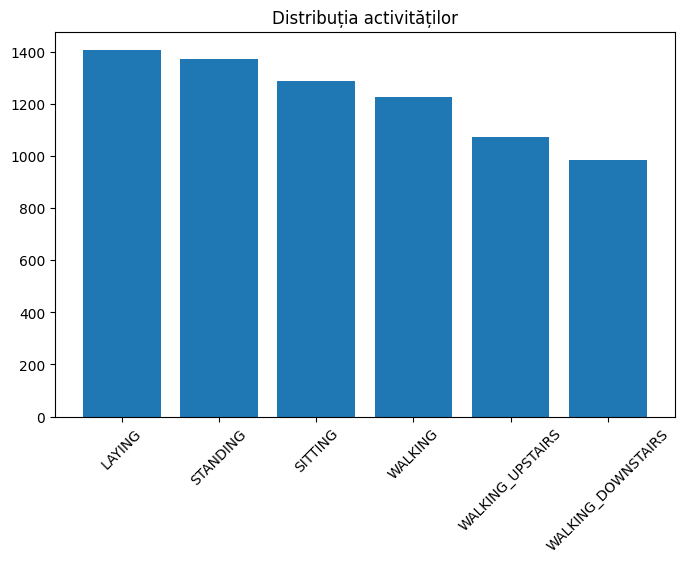

In [27]:
plt.figure(figsize=(8,5))
plt.bar(activity_counts_pd["Activity"], activity_counts_pd["count"])
plt.xticks(rotation=45)
plt.title("Distribuția activităților")
plt.show()

Datele sunt destul de egal distribuite între clase și nu este nevoie de undersampling/ oversampling.

###Vizualizare distribuție activități pe participanți

Verificăm dacă fiecare persoană a contribuit relativ uniform la toate activitățile.

In [28]:
activity_subject = (
    train.groupBy("subject", "Activity").count().orderBy("subject", "Activity")
) # agregare în Spark

In [29]:
activity_subject_pd = activity_subject.toPandas()

In [30]:
pivot = activity_subject_pd.pivot(index="subject", columns="Activity", values="count")

Plotare heatmap

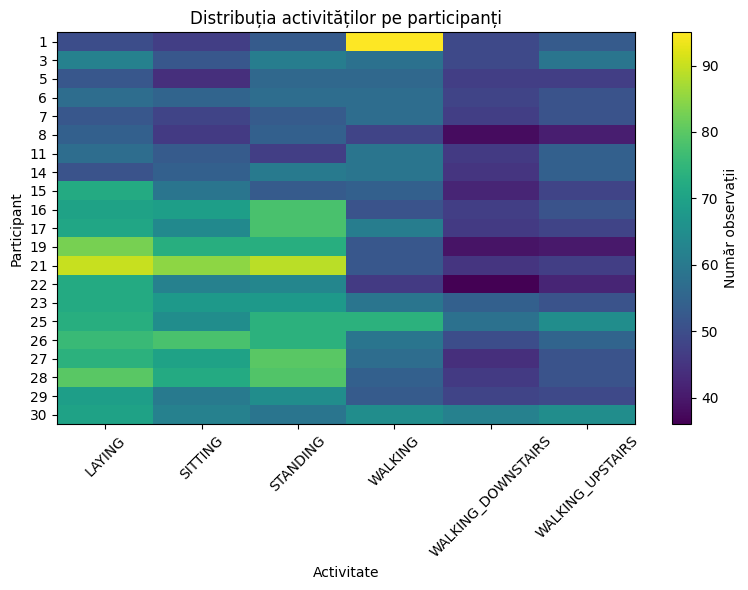

In [31]:
plt.figure(figsize=(8,6))
plt.imshow(pivot, aspect="auto")
plt.colorbar(label="Număr observații")

plt.xticks(range(len(pivot.columns)), pivot.columns, rotation=45)
plt.yticks(range(len(pivot.index)), pivot.index)

plt.xlabel("Activitate")
plt.ylabel("Participant")
plt.title("Distribuția activităților pe participanți")

plt.tight_layout()
plt.show()

Dataset-ul e relativ echilibrat per total, dar nu perfect uniform la nivel individual - există variație naturală între subiecți, mai ales la activitățile statice.

Observăm totuși că subiectul 1 are peste media înregistrărilor la activi. 'Walking'. Eliminarea completă a subiectului ar însemna pierderea a ~400 de înregistrări, o pierdere disproporționată la doar 21 de subiecți disponibili în train. Decidem să păstrăm datele.

###Vizualizăm statistici pe grupuri de activități

Agregările realizate în această etapă se aplică asupra celor 561 de caracteristici statistice calculate din semnalele brute, cu scopul de a analiza distribuția lor în funcție de activitatea desfășurată sau de participant.


Analiza caracteristicilor pe activitate. Un atribut e util pentru clasificare doar dacă valorile lui diferă vizibil între clase.

Pentru fiecare tip de activitate se calculează media, deviația standard, valoarea minimă și maximă ale caracteristicii tBodyAcc-mean()-X. Aceste statistici evidențiază diferențele dintre activitățile desfășurate. tBodyAcc-mean()-X reprezintă media accelerației corpului pe axa X, calculată în domeniul timpului pentru fiecare fereastră temporală de aproximativ 2,56 secunde.

In [32]:
# Agregare pe activitate
train.groupBy("Activity").agg(
    F.avg("tBodyAcc-mean()-X"),
    F.stddev("tBodyAcc-mean()-X"),
    F.min("tBodyAcc-mean()-X"),
    F.max("tBodyAcc-mean()-X")
).show()

+------------------+----------------------+-------------------------+----------------------+----------------------+
|          Activity|avg(tBodyAcc-mean()-X)|stddev(tBodyAcc-mean()-X)|min(tBodyAcc-mean()-X)|max(tBodyAcc-mean()-X)|
+------------------+----------------------+-------------------------+----------------------+----------------------+
|            LAYING|   0.26919100708877036|      0.10154141754940861|                  -1.0|                   1.0|
|WALKING_DOWNSTAIRS|   0.28816888847565925|       0.0951013452962246|           -0.16108761|            0.61759696|
|           WALKING|   0.27626020087275704|      0.05035283779104986|            0.12146517|            0.43325583|
|          STANDING|    0.2792937570742358|      0.02009713840644646|            0.11123126|             0.6315101|
|  WALKING_UPSTAIRS|   0.26192952725200364|      0.07802865314238458|          -0.061041328|            0.48018027|
|           SITTING|    0.2734489988254276|      0.04199752597460006|   

Investigăm puțin câți outlineri avem pentru activitatea 'Laying' întrucât are exact limitele extreme ale intervalului de normalizare.

In [33]:
train.filter(
    (F.col("Activity") == "LAYING") &
    ((F.col("tBodyAcc-mean()-X") == -1.0) | (F.col("tBodyAcc-mean()-X") == 1.0))
).count()

2

In [34]:
spark.sql("""
SELECT
    Activity,
    AVG(`tBodyAcc-mean()-X`) AS avg_acc_x,
    STDDEV(`tBodyAcc-mean()-X`) AS std_acc_x,
    MIN(`tBodyAcc-mean()-X`) AS min_acc_x,
    MAX(`tBodyAcc-mean()-X`) AS max_acc_x
FROM train
GROUP BY Activity
""").show()

+------------------+-------------------+-------------------+------------+----------+
|          Activity|          avg_acc_x|          std_acc_x|   min_acc_x| max_acc_x|
+------------------+-------------------+-------------------+------------+----------+
|            LAYING|0.26919100708877036|0.10154141754940861|        -1.0|       1.0|
|WALKING_DOWNSTAIRS|0.28816888847565925| 0.0951013452962246| -0.16108761|0.61759696|
|           WALKING|0.27626020087275704|0.05035283779104986|  0.12146517|0.43325583|
|          STANDING| 0.2792937570742358|0.02009713840644646|  0.11123126| 0.6315101|
|  WALKING_UPSTAIRS|0.26192952725200364|0.07802865314238458|-0.061041328|0.48018027|
|           SITTING| 0.2734489988254276|0.04199752597460006| -0.41265906|0.55913494|
+------------------+-------------------+-------------------+------------+----------+



Analiza datelor în funcție de participant. Un atribut bun ar trebui să varieze în funcție de activitate, nu de identitatea persoanei.

Se calculează media unor caracteristici pentru fiecare participant pentru a observa distribuția valorilor caracteristicilor pentru fiecare participant și a identifica eventuale variații între înregistrările asociate acestora.

In [35]:
# Agregare pe subiect/ participant
train.groupBy("subject").agg(
    F.avg("tBodyAcc-mean()-X"),
    F.avg("tBodyAcc-std()-X")
).show()

+-------+----------------------+---------------------+
|subject|avg(tBodyAcc-mean()-X)|avg(tBodyAcc-std()-X)|
+-------+----------------------+---------------------+
|      1|    0.2656969205821327|  -0.5457953313283258|
|      6|   0.27237661418153847|  -0.5050860850720617|
|     16|   0.27788744037431684|  -0.6681614982986342|
|      3|    0.2734287196363637|  -0.6234136020469211|
|      5|    0.2791779603013242|  -0.5076910113917221|
|     19|    0.2697234871055558|  -0.5746589229191947|
|     15|    0.2782134072500001|  -0.5565411730893293|
|     17|    0.2740295480652174|  -0.6084552438707336|
|      8|   0.27075906329537364|   -0.582958863017438|
|      7|    0.2702116978149351|   -0.577518324748052|
|     21|   0.27746652552205886|   -0.672323867377451|
|     11|   0.27658531139556963|    -0.58947649779557|
|     14|   0.27018459600928835|  -0.6116711182160992|
|     28|   0.27753255476439764|  -0.6490403913078533|
|     26|       0.2730365808625|  -0.6231010311683677|
|     27| 

In [36]:
spark.sql("""
SELECT
    subject,
    AVG(`tBodyAcc-mean()-X`) AS avg_acc_x,
    AVG(`tBodyAcc-std()-X`) AS avg_std_acc_x
FROM train
GROUP BY subject
""").show()

+-------+-------------------+-------------------+
|subject|          avg_acc_x|      avg_std_acc_x|
+-------+-------------------+-------------------+
|      1| 0.2656969205821327|-0.5457953313283258|
|      6|0.27237661418153847|-0.5050860850720617|
|     16|0.27788744037431684|-0.6681614982986342|
|      3| 0.2734287196363637|-0.6234136020469211|
|      5| 0.2791779603013242|-0.5076910113917221|
|     19| 0.2697234871055558|-0.5746589229191947|
|     15| 0.2782134072500001|-0.5565411730893293|
|     17| 0.2740295480652174|-0.6084552438707336|
|      8|0.27075906329537364| -0.582958863017438|
|      7| 0.2702116978149351| -0.577518324748052|
|     21|0.27746652552205886| -0.672323867377451|
|     11|0.27658531139556963|  -0.58947649779557|
|     14|0.27018459600928835|-0.6116711182160992|
|     28|0.27753255476439764|-0.6490403913078533|
|     26|    0.2730365808625|-0.6231010311683677|
|     27|  0.277264567074468|-0.6609760852180854|
|     22| 0.2747676900461059|-0.5460899755486919|


Statistici globale

In [37]:
# Agregare generala
train.select(
    F.avg("tBodyAcc-mean()-X"),
    F.stddev("tBodyAcc-mean()-X")
).show()

+----------------------+-------------------------+
|avg(tBodyAcc-mean()-X)|stddev(tBodyAcc-mean()-X)|
+----------------------+-------------------------+
|   0.27448812496352026|      0.07026133266614945|
+----------------------+-------------------------+



In [38]:
spark.sql("""
SELECT
    AVG(`tBodyAcc-mean()-X`) AS avg_acc_x,
    STDDEV(`tBodyAcc-mean()-X`) AS std_acc_x
FROM train
""").show()

+-------------------+-------------------+
|          avg_acc_x|          std_acc_x|
+-------------------+-------------------+
|0.27448812496352026|0.07026133266614945|
+-------------------+-------------------+



# Prelucrare date

Eliminarea caracteristicilor puternic corelate. În setul de date există un număr mare de caracteristici extrase din aceleași semnale ale accelerometrului și giroscopului. Multe dintre acestea sunt puternic corelate și transmit informații similare. Pentru a reduce redundanța și dimensionalitatea setului de date, sunt eliminate caracteristicile care prezintă un coeficient de corelație peste un prag prestabilit.

In [39]:
feature_cols = [
    c for c in train.columns
    if c not in ["Activity", "subject"]
]

### Corr matrix

Asamblăm toate caracteristicile într-un singur vector.

In [279]:
corr_assembler = VectorAssembler(inputCols=feature_cols, outputCol="corr_features") # definim VectorAssembler
vector_df = corr_assembler.transform(train).select("corr_features") # transformăm

Calculul propriu-zis al matricei de corelație se face distribuit, în Spark.

In [280]:
corr_matrix_spark = Correlation.corr(vector_df, "corr_features", method="pearson").head()[0]

In [282]:
corr_matrix = pd.DataFrame( # tabel Pandas
    corr_matrix_spark.toArray(), # numpy.ndarray
    columns=feature_cols,
    index=feature_cols
).abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

threshold = 0.95
to_drop = [
    c for c in upper.columns
    if any(upper[c] > threshold)
]

In [44]:
train_remained = train.drop(*to_drop)
test_remained = test.drop(*to_drop)

In [45]:
feature_cols_remained = [
    c for c in train_remained.columns
    if c not in ["Activity", "subject"]
]

print(f"Features rămase după filtrul de corelație: {len(feature_cols_remained)}")

Features rămase după filtrul de corelație: 253


###Filtru discriminare și subject leakage

Investigăm cât de mult variază media atributului între activități/subiecți și renuntăm la atribute care nu diferă între activități și atribute care variază mai mult pe persoană.

In [46]:
activity_agg = train_remained.groupBy("Activity").agg(  # job Spark
    *[F.avg(c).alias(c) for c in feature_cols_remained]
).toPandas().set_index("Activity")

In [47]:
subject_agg = train_remained.groupBy("subject").agg(  # job Spark
    *[F.avg(c).alias(c) for c in feature_cols_remained]
).toPandas().set_index("subject")

In [48]:
activity_spread = activity_agg.max() - activity_agg.min() # cât de mult variază media atributului între activități/subiecți
subject_spread = subject_agg.max() - subject_agg.min()

In [49]:
comparison_df = pd.DataFrame({
    "activity_spread": activity_spread,
    "subject_spread": subject_spread
})

In [50]:
comparison_df["ratio"] = comparison_df["activity_spread"] / (comparison_df["subject_spread"] + 1e-6)

Filtru pt atribute care nu diferă între activități

In [51]:
threshold_discrimination = comparison_df["activity_spread"].quantile(0.05) # cuantila

low_discrimination_features = comparison_df[
    comparison_df["activity_spread"] < threshold_discrimination
].index.tolist() # eliminam cele mai slabe 5% dintre atribute la a diferenția activitățile

In [52]:
print(f"Atribute cu discriminare slabă (eliminate): {len(low_discrimination_features)}")


Atribute cu discriminare slabă (eliminate): 13


 Filtru pt subject leakage

In [53]:
threshold_leakage = 1.0  # raport < 1 variază mai mult pe subiect decât pe activitate

risky_features = comparison_df[
    comparison_df["ratio"] < threshold_leakage
].index.tolist()

In [54]:
print(f"Atribute cu risc de subject leakage (eliminate): {len(risky_features)}")

Atribute cu risc de subject leakage (eliminate): 66


In [55]:
features_to_drop = set(low_discrimination_features) | set(risky_features)

In [56]:
feature_cols_final = [
    c for c in feature_cols_remained
    if c not in features_to_drop
]

print(f"Features finale (păstrate): {len(feature_cols_final)}")

Features finale (păstrate): 183


###Vectorul de caracteristici

Construirea vectorului de caracteristici. După selectarea caracteristicilor utilizate în model, acestea sunt combinate într-o singură coloană de tip vector cu ajutorul clasei VectorAssembler.

In [57]:
assembler = VectorAssembler(
    inputCols=feature_cols_final,
    outputCol="features"
)

# train_features = assembler.transform(train_remained)
# test_features = assembler.transform(test_remained)

###Scalarea

Am văzut că majoritatea observațiilor au valori în intervalul [-1,1]. Cu toate acestea, a fost aplicată o etapă suplimentară de standardizare utilizând StandardScaler, pentru a aduce caracteristicile la o medie apropiată de 0 și o deviație standard apropiată de 1.

Cum 'features' este un DenseVector vom normaliza datele standard, prin translatare si scalare. Pentru un SparseVector am fi folosit 'withMean=False' pentru a economisi memorie.

In [58]:
scaler = StandardScaler(
    inputCol="features",
    outputCol="scaled_features",
    withMean=True,
    withStd=True
)

# scaler_model = scaler.fit(train_features)

# train_scaled = scaler_model.transform(train_features)
# test_scaled = scaler_model.transform(test_features)

###Facem analiza PCA

Aplicăm metoda Principal Component Analysis pentru reducerea dimensionalității setului de date.

In [59]:
pca = PCA(
    k=75,
    inputCol="scaled_features",
    outputCol="pca_features"
)

# pca_model = pca.fit(train_scaled)

# train_pca = pca_model.transform(train_scaled)
# test_pca = pca_model.transform(test_scaled)

In [34]:
# explained = pca_model.explainedVariance

# print("Total explained variance:", float(explained.sum()))

Total explained variance: 0.9325588778219501


Convertim Activity (string) in label (int)

In [60]:
indexer = StringIndexer(
    inputCol="Activity",
    outputCol="label"
)

# label_model = indexer.fit(train_pca)

# train_final = label_model.transform(train_pca)
# test_final = label_model.transform(test_pca)

#Pipeline

In [61]:
def create_pipeline(classifier):
    return Pipeline(stages=[
        assembler,
        scaler,
        pca,
        indexer,
        classifier
    ])

# Model training

###Multinomial Logistic Regression

Drept primă metodă ML de clasificare am ales Multinomial Logistic Regression deoarece este proiectată pentru probleme de clasificare multiclasă și funcționează bine pe caracteristici numerice continue precum cele extrase din semnalele accelerometrului și giroscopului. De asemenea, metoda beneficiază de caracteristici standardizate și de reducerea dimensionalității prin PCA.

In [62]:
lr = LogisticRegression(
    featuresCol="pca_features",
    labelCol="label",
    predictionCol="prediction",
    probabilityCol="probability",
    maxIter=100,
    regParam=0.0,
    elasticNetParam=0.0,
    family="multinomial"
)

In [63]:
lr_pipeline = create_pipeline(lr)

In [ ]:
# lr_model = lr.fit(train_final)

In [64]:
pipeline_model_lr = lr_pipeline.fit(train_remained)

In [65]:
# print("Number of classes:", lr_model.numClasses)
# print("Number of features:", lr_model.numFeatures)

# print("Intercepts:")
# print(lr_model.interceptVector)

In [ ]:
# summary = lr_model.evaluate(test_final)
# print("Summary accuracy:", summary.accuracy)

Summary accuracy: 0.8798778418730913


In [ ]:
# predictions = lr_model.transform(test_final)

In [66]:
predictions = pipeline_model_lr.transform(test_remained)

In [67]:
predictions.select(
    "label",
    "prediction",
    "probability"
).show(10, truncate=False)

+-----+----------+-----------------------------------------------------------------------------------------------------------------------------------+
|label|prediction|probability                                                                                                                        |
+-----+----------+-----------------------------------------------------------------------------------------------------------------------------------+
|1.0  |1.0       |[4.469860618676957E-21,0.9990217919174615,9.782080825384513E-4,9.692325129617541E-26,2.0781374016649072E-24,2.2684881158402326E-22]|
|1.0  |1.0       |[6.641069754845842E-33,0.843583621737663,0.15641637826233704,3.25036417237318E-33,3.7906118328809456E-33,3.305030416373537E-34]    |
|1.0  |1.0       |[4.0757973271881954E-27,0.9870168037085278,0.012983196291462473,9.706957646823726E-15,9.276103717269939E-38,1.59654637232681E-29]  |
|1.0  |1.0       |[3.642921293478735E-32,0.9376111445974488,0.062388855402551145,6.79043442959

Folosim MulticlassClassificationEvaluator

In [68]:
metrics = ["accuracy", "f1", "weightedPrecision", "weightedRecall"]

for metric in metrics:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric
    )

    score = evaluator.evaluate(predictions)
    print(f"{metric}: {score:.4f}")

accuracy: 0.9162
f1: 0.9160
weightedPrecision: 0.9182
weightedRecall: 0.9162


Confusion Matrix

In [69]:
label_model = next(
    stage for stage in pipeline_model_lr.stages
    if isinstance(stage, StringIndexerModel)
)

In [70]:
prediction_converter = IndexToString(
    inputCol="prediction",
    outputCol="predicted_activity",
    labels=label_model.labels
)

predictions_named = prediction_converter.transform(predictions)

In [71]:
label_converter = IndexToString(
    inputCol="label",
    outputCol="actual_activity",
    labels=label_model.labels
)

predictions_named = label_converter.transform(predictions_named)

In [72]:
confusion_matrix_sp = (
    predictions_named
    .groupBy("actual_activity")
    .pivot("predicted_activity")
    .count()
    .fillna(0)
    .orderBy("actual_activity")
)

In [73]:
confusion_matrix_sp.show(truncate=False)

+------------------+------+-------+--------+-------+------------------+----------------+
|actual_activity   |LAYING|SITTING|STANDING|WALKING|WALKING_DOWNSTAIRS|WALKING_UPSTAIRS|
+------------------+------+-------+--------+-------+------------------+----------------+
|LAYING            |534   |0      |0       |2      |1                 |0               |
|SITTING           |1     |426    |56      |6      |0                 |2               |
|STANDING          |0     |37     |490     |5      |0                 |0               |
|WALKING           |0     |0      |1       |480    |6                 |9               |
|WALKING_DOWNSTAIRS|0     |0      |1       |20     |354               |45              |
|WALKING_UPSTAIRS  |0     |3      |1       |43     |8                 |416             |
+------------------+------+-------+--------+-------+------------------+----------------+



###Decision Tree Classifier

Algoritmul Decision Tree Classifier poate modela relații neliniare dintre caracteristici și clasele țintă, fără a presupune existența unei relații liniare între acestea. Caracteristicile extrase din semnalele accelerometrului și giroscopului pot prezenta relații complexe cu activitățile desfășurate, iar arborii de decizie sunt capabili să identifice automat regulile de clasificare pe baza valorilor acestor caracteristici.

In [74]:
dt = DecisionTreeClassifier(
    featuresCol="pca_features",
    labelCol="label",
    predictionCol="prediction",
    maxDepth=10,
    seed=42
)

In [75]:
dt_pipeline = create_pipeline(dt)

In [ ]:
# dt_model = dt.fit(train_final)

In [76]:
pipeline_model_dt = dt_pipeline.fit(train_remained)

Inspectam arborele

In [ ]:
# predictions = dt_model.transform(test_final)

In [77]:
predictions = pipeline_model_dt.transform(test_remained)

MulticlassClassificationEvaluator

In [78]:
for metric in metrics:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric
    )

    score = evaluator.evaluate(predictions)
    print(f"{metric}: {score:.4f}")

accuracy: 0.7696
f1: 0.7694
weightedPrecision: 0.7730
weightedRecall: 0.7696


In [79]:
predictions.select(
    "label",
    "prediction",
    "probability"
).show(10, truncate=False)

+-----+----------+-------------------------------------------------------------------------------------------------------+
|label|prediction|probability                                                                                            |
+-----+----------+-------------------------------------------------------------------------------------------------------+
|1.0  |1.0       |[0.00392156862745098,0.9509803921568627,0.0392156862745098,0.00196078431372549,0.00392156862745098,0.0]|
|1.0  |1.0       |[0.0,0.9166666666666666,0.08333333333333333,0.0,0.0,0.0]                                               |
|1.0  |1.0       |[0.00392156862745098,0.9509803921568627,0.0392156862745098,0.00196078431372549,0.00392156862745098,0.0]|
|1.0  |1.0       |[0.00392156862745098,0.9509803921568627,0.0392156862745098,0.00196078431372549,0.00392156862745098,0.0]|
|1.0  |1.0       |[0.0,0.975609756097561,0.024390243902439025,0.0,0.0,0.0]                                               |
|1.0  |1.0      

Confusion matrix

In [80]:
predictions_pred = prediction_converter.transform(predictions)

In [81]:
predictions_named = label_converter.transform(predictions_pred)

In [82]:
confusion_matrix_sp = (
    predictions_named
    .groupBy("actual_activity")
    .pivot("predicted_activity")
    .count()
    .fillna(0)
    .orderBy("actual_activity")
)

confusion_matrix_sp.show(truncate=False)

+------------------+------+-------+--------+-------+------------------+----------------+
|actual_activity   |LAYING|SITTING|STANDING|WALKING|WALKING_DOWNSTAIRS|WALKING_UPSTAIRS|
+------------------+------+-------+--------+-------+------------------+----------------+
|LAYING            |489   |36     |12      |0      |0                 |0               |
|SITTING           |7     |357    |126     |1      |0                 |0               |
|STANDING          |1     |116    |415     |0      |0                 |0               |
|WALKING           |1     |2      |2       |424    |44                |23              |
|WALKING_DOWNSTAIRS|1     |2      |4       |101    |247               |65              |
|WALKING_UPSTAIRS  |0     |11     |7       |44     |73                |336             |
+------------------+------+-------+--------+-------+------------------+----------------+



###Random forest classifier

Algoritmul Random Forest Classifier a fost ales deoarece reprezintă o metodă de tip ensemble, care construiește mai mulți arbori de decizie pe subseturi diferite ale datelor și combină predicțiile acestora prin vot majoritar. În cazul setului de date ales, Random Forest poate identifica relații complexe între caracteristici și activitățile desfășurate, fiind în același timp mai puțin predispus la supraînvățare.

In [83]:
rf = RandomForestClassifier(
    featuresCol="pca_features",
    labelCol="label",
    predictionCol="prediction",
    numTrees=100,
    maxDepth=10,
    seed=42
)

In [84]:
rf_pipeline = create_pipeline(rf)

In [ ]:
# rf_model = rf.fit(train_final)

In [85]:
pipeline_model_rf = rf_pipeline.fit(train_remained)

In [ ]:
# print(rf_model.featureImportances)

(75,[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74],[0.18028537311526388,0.04736348089682954,0.04882621604349183,0.13938818326368688,0.05152501612785929,0.04283301065160801,0.02580342186677806,0.029322481381373847,0.019886693565169363,0.017936359299088555,0.015083206763721544,0.013659686536586222,0.005386812414839374,0.006880789359527625,0.00742123681188463,0.012320884536490538,0.02025108540865966,0.01600361531400957,0.01020717290448921,0.005553413848807252,0.011490078196658532,0.02087433445319129,0.007752726127356588,0.010117073949928128,0.004104821583944521,0.006464290407058106,0.008739307092540304,0.004677550322700646,0.004739355145969887,0.003864220262790295,0.007484562171274867,0.003628735083555407,0.004970721547710109,0.005423089670165983,0.003912449111671558,0.004784779724404164,0.0074267126507753314,0.0065188454

In [ ]:
# predictions = rf_model.transform(test_final)

In [86]:
predictions = pipeline_model_rf.transform(test_remained)

In [87]:
predictions.select(
    "label",
    "prediction",
    "probability"
).show(10, truncate=False)

+-----+----------+----------------------------------------------------------------------------------------------------------------------------+
|label|prediction|probability                                                                                                                 |
+-----+----------+----------------------------------------------------------------------------------------------------------------------------+
|1.0  |1.0       |[0.061654430115984725,0.6672516497113911,0.19138500811770306,0.01785572489557822,0.03620071828877224,0.025652468870570756]  |
|1.0  |1.0       |[0.04267401514658348,0.6338008341954886,0.2808784849687376,0.012233433385853972,0.012032959779672347,0.018380272523664233]  |
|1.0  |1.0       |[0.06465289285496309,0.7071353857784876,0.1711879557652406,0.013711029737397296,0.017450879433456294,0.025861856430455226]  |
|1.0  |1.0       |[0.03164592426046753,0.7856884423673722,0.14395088519106303,0.02233611443682628,0.00773867114157652,0.0086399626026944

In [88]:
for metric in metrics:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric
    )

    score = evaluator.evaluate(predictions)
    print(f"{metric}: {score:.4f}")

accuracy: 0.8616
f1: 0.8598
weightedPrecision: 0.8659
weightedRecall: 0.8616


Confusion matrix

In [89]:
predictions_pred = prediction_converter.transform(predictions)

In [90]:
predictions_named = label_converter.transform(predictions_pred)

In [91]:
confusion_matrix_sp = (
    predictions_named
    .groupBy("actual_activity")
    .pivot("predicted_activity")
    .count()
    .fillna(0)
    .orderBy("actual_activity")
)

confusion_matrix_sp.show(truncate=False)

+------------------+------+-------+--------+-------+------------------+----------------+
|actual_activity   |LAYING|SITTING|STANDING|WALKING|WALKING_DOWNSTAIRS|WALKING_UPSTAIRS|
+------------------+------+-------+--------+-------+------------------+----------------+
|LAYING            |525   |4      |8       |0      |0                 |0               |
|SITTING           |4     |353    |134     |0      |0                 |0               |
|STANDING          |0     |48     |484     |0      |0                 |0               |
|WALKING           |0     |1      |0       |471    |21                |3               |
|WALKING_DOWNSTAIRS|0     |1      |3       |76     |295               |45              |
|WALKING_UPSTAIRS  |0     |2      |4       |22     |32                |411             |
+------------------+------+-------+--------+-------+------------------+----------------+



# Optimizare hiperparametri

###Multinomial Logistic Regression

Impartim setul de date de train pentru alegerea hiperparametrilor.



In [92]:
subjects = [row["subject"] for row in train_remained.select("subject").distinct().collect()] # lista cu participanții

In [93]:
np.random.seed(42)
np.random.shuffle(subjects) # amestecăm participanții (nu rândurile)

Vom împarți datele de antrenare (observațiile venite de la participanți) împarțind participanții.

RandomSplit([0.8, 0.2]) ar împărți rândurile la întâmplare, ceea ce înseamnă că ferestre de semnal ale aceluiași subiect ar putea ajunge și în setul de validare și in setul de antrenare, iar modelul ar putea recunoaște stilul de mișcare al persoanei.

In [94]:
n_val_subjects = int(len(subjects) * 0.2)
validation_subjects = subjects[:n_val_subjects]
train_subjects = subjects[n_val_subjects:]

In [95]:
train_tune = train_remained.filter(F.col("subject").isin(train_subjects))
validation = train_remained.filter(F.col("subject").isin(validation_subjects))

Asfel sutnem siguri că setul validation conține doar participanți pe care modelul nu i-a văzut deloc în train_tune.

In [96]:
evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName="accuracy"
    )

In [97]:
def evaluate_logistic_regression(
    train_data,
    validation_data,
    reg_param,
    max_iter,
    elastic_net=0.0
):

    lr = LogisticRegression(
        featuresCol="pca_features",
        labelCol="label",
        predictionCol="prediction",
        probabilityCol="probability",
        family="multinomial",
        regParam=reg_param,
        maxIter=max_iter,
        elasticNetParam=elastic_net
    )

    pipeline = create_pipeline(lr)

    model = pipeline.fit(train_data)

    train_pred = model.transform(train_data)
    validation_pred = model.transform(validation_data)

    train_acc = evaluator.evaluate(train_pred)
    validation_acc = evaluator.evaluate(validation_pred)

    gap = train_acc - validation_acc

    return train_acc, validation_acc, gap

Grid Search

In [98]:
reg_params = [0.001, 0.01, 0.1]
max_iters = [50, 100, 200]

results = []

for reg in reg_params:
    for it in max_iters:

        train_acc, val_acc, gap = evaluate_logistic_regression(train_tune,validation,reg,it)

        results.append({
            "regParam": reg,
            "maxIter": it,
            "Train Accuracy": train_acc,
            "Validation Accuracy": val_acc,
            "Gap": gap
        })

In [99]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["Validation Accuracy", "Gap"],
    ascending=[False, True]
)

In [100]:
results_df

,regParam,maxIter,Train Accuracy,Validation Accuracy,Gap
0,0.001,50,0.960216,0.933803,0.026413
1,0.001,100,0.960216,0.933803,0.026413
2,0.001,200,0.960216,0.933803,0.026413
3,0.010,50,0.950775,0.930986,0.019790
4,0.010,100,0.950775,0.930986,0.019790
5,0.010,200,0.950775,0.930986,0.019790
6,0.100,50,0.934761,0.925352,0.009409
7,0.100,100,0.934761,0.925352,0.009409
8,0.100,200,0.934761,0.925352,0.009409


Alegem cel mai bun model

In [101]:
best = results_df.iloc[0]

best_reg = best["regParam"]
best_iter = int(best["maxIter"])

Antrenam pe toate datele de train

In [102]:
best_lr = LogisticRegression(
    featuresCol="pca_features",
    labelCol="label",
    predictionCol="prediction",
    probabilityCol="probability",
    family="multinomial",
    regParam=best_reg,
    maxIter=best_iter,
    elasticNetParam=0.0
)

best_pipeline = create_pipeline(best_lr)

final_model = best_pipeline.fit(train_remained)

Evaluam pe datele de test

In [103]:
test_predictions = final_model.transform(test_remained)

test_accuracy = evaluator.evaluate(test_predictions)

print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.9212758737699356


###Decision Tree optimizare hiperparametri

Imparțire set de date de train

In [104]:
subjects = [row["subject"] for row in train_remained.select("subject").distinct().collect()]

np.random.seed(42)
np.random.shuffle(subjects)

In [105]:
n_val_subjects = int(len(subjects) * 0.2)
validation_subjects = subjects[:n_val_subjects]
train_subjects = subjects[n_val_subjects:]

train_tune = train_remained.filter(F.col("subject").isin(train_subjects))
validation = train_remained.filter(F.col("subject").isin(validation_subjects))

Definim functia de evaluare

In [106]:
def evaluate_decision_tree(
    train_data,
    validation_data,
    max_depth,
    min_instances_per_node=1,
    impurity="gini"
):
    dt = DecisionTreeClassifier(
        featuresCol="pca_features",
        labelCol="label",
        predictionCol="prediction",
        maxDepth=max_depth,
        minInstancesPerNode=min_instances_per_node,
        impurity=impurity,
        seed=42
    )

    pipeline = create_pipeline(dt)

    model = pipeline.fit(train_data)

    train_pred = model.transform(train_data)
    validation_pred = model.transform(validation_data)

    train_acc = evaluator.evaluate(train_pred)
    validation_acc = evaluator.evaluate(validation_pred)

    gap = train_acc - validation_acc

    return train_acc, validation_acc, gap

Creăm un Grid Search

In [107]:
max_depths = [5, 10, 15, 20]
min_instances_list = [1, 5, 10]

dt_results = []

for md in max_depths:
    for mi in min_instances_list:

        train_acc, val_acc, gap = evaluate_decision_tree(
            train_tune,
            validation,
            md,
            mi
        )

        dt_results.append({
            "maxDepth": md,
            "minInstancesPerNode": mi,
            "Train Accuracy": train_acc,
            "Validation Accuracy": val_acc,
            "Gap": gap
        })

        print(f"maxDepth={md}, minInstancesPerNode={mi} -> "
              f"train={train_acc:.4f}, val={val_acc:.4f}, gap={gap:.4f}")

maxDepth=5, minInstancesPerNode=1 -> train=0.7893, val=0.8085, gap=-0.0192
maxDepth=5, minInstancesPerNode=5 -> train=0.7884, val=0.8085, gap=-0.0200
maxDepth=5, minInstancesPerNode=10 -> train=0.7883, val=0.8106, gap=-0.0223
maxDepth=10, minInstancesPerNode=1 -> train=0.9565, val=0.7887, gap=0.1678
maxDepth=10, minInstancesPerNode=5 -> train=0.9203, val=0.7810, gap=0.1393
maxDepth=10, minInstancesPerNode=10 -> train=0.8898, val=0.8176, gap=0.0721
maxDepth=15, minInstancesPerNode=1 -> train=0.9987, val=0.7810, gap=0.2177
maxDepth=15, minInstancesPerNode=5 -> train=0.9322, val=0.7725, gap=0.1597
maxDepth=15, minInstancesPerNode=10 -> train=0.8928, val=0.8225, gap=0.0702
maxDepth=20, minInstancesPerNode=1 -> train=1.0000, val=0.7789, gap=0.2211
maxDepth=20, minInstancesPerNode=5 -> train=0.9322, val=0.7725, gap=0.1597
maxDepth=20, minInstancesPerNode=10 -> train=0.8928, val=0.8225, gap=0.0702


Creăm DataFrame-ul cu rezultatele

In [108]:
dt_results_df = pd.DataFrame(dt_results)

dt_results_df = dt_results_df.sort_values(
    by=["Validation Accuracy", "Gap"],
    ascending=[False, True]
)

In [109]:
dt_results_df

,maxDepth,minInstancesPerNode,Train Accuracy,Validation Accuracy,Gap
8,15,10,0.892785,0.822535,0.070250
11,20,10,0.892785,0.822535,0.070250
5,10,10,0.889751,0.817606,0.072145
2,5,10,0.788267,0.810563,-0.022296
1,5,5,0.788436,0.808451,-0.020015
0,5,1,0.789278,0.808451,-0.019172
3,10,1,0.956507,0.788732,0.167775
4,10,5,0.920263,0.780986,0.139277
6,15,1,0.998651,0.780986,0.217665
9,20,1,1.000000,0.778873,0.221127


In [110]:
best_row = dt_results_df.iloc[0]
best_max_depth = int(best_row["maxDepth"])
best_min_instances = int(best_row["minInstancesPerNode"])


Reantrenăm pe tot train-ul

In [111]:
final_dt = DecisionTreeClassifier(
    featuresCol="pca_features",
    labelCol="label",
    predictionCol="prediction",
    maxDepth=best_max_depth,
    minInstancesPerNode=best_min_instances,
    impurity="gini",
    seed=42
)

final_pipeline = create_pipeline(final_dt)

final_model = final_pipeline.fit(train_remained)

In [112]:
test_predictions = final_model.transform(test_remained)

test_accuracy = evaluator.evaluate(test_predictions)

print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.7750254496097726


Pentru modelele Multinomial Logistic Regression și Decision Tree, optimizarea hiperparametrilor a fost realizată manual printr-un Grid Search. Pentru fiecare combinație de hiperparametri a fost antrenat un model pe setul de antrenare, iar performanța a fost evaluată pe setul de validare. Alegerea modelului s-a făcut pe baza acurateții obținute pe setul de validare.

###Optimizare hiperparametri Random Forest

CrossValidator din Spark ML face k-fold random by default și la fel ca randomSplit nu respectă gruparea pe participant.

Pentru optimizarea parametrilor vom avea o tactică diferită.
În loc de un singur split 80/20, împarțim participanții în k grupuri, iar de fiecare dată, un grup e validare, restul sunt folosite la antrenare.

In [113]:
def create_subject_folds(df, subject_col="subject", k=5, seed=42):
    subjects = [row[subject_col] for row in df.select(subject_col).distinct().collect()]

    np.random.seed(seed)
    np.random.shuffle(subjects)

    folds = np.array_split(subjects, k)
    return [list(f) for f in folds] # transformăm în listă Python

In [114]:
subject_folds = create_subject_folds(train_remained, k=5, seed=42)

Definim fcț. care rulează un singur fold.

In [115]:
def evaluate_rf_on_fold(train_data, validation_data, num_trees, max_depth):
    rf = RandomForestClassifier(
        featuresCol="pca_features",
        labelCol="label",
        predictionCol="prediction",
        numTrees=num_trees,
        maxDepth=max_depth,
        seed=42
    )

    pipeline = create_pipeline(rf)
    model = pipeline.fit(train_data)

    train_pred = model.transform(train_data)
    val_pred = model.transform(validation_data)

    train_acc = evaluator.evaluate(train_pred)
    val_acc = evaluator.evaluate(val_pred)

    return train_acc, val_acc

Definim fct. care rulează toate fold-urile.

In [116]:
def cross_validate_rf(df, subject_folds, num_trees, max_depth, subject_col="subject"):
    fold_results = []

    for i, val_subjects in enumerate(subject_folds): # for index, lista
        train_subjects = [ s for j, fold in enumerate(subject_folds) if j != i for s in fold ] # restul participantilor (din celelalte fold-uri) merg la antrenare

        train_fold = df.filter(F.col(subject_col).isin(train_subjects))
        val_fold = df.filter(F.col(subject_col).isin(val_subjects))

        train_acc, val_acc = evaluate_rf_on_fold(train_fold, val_fold, num_trees, max_depth)

        fold_results.append({
            "fold": i,
            "train_acc": train_acc,
            "val_acc": val_acc,
            "gap": train_acc - val_acc
        })

    return fold_results

Grid Search și CrossValidation pt fiecare combinatie de parametrii

In [117]:
num_trees_list = [50, 100, 200]
max_depth_list = [5, 10, 15]

all_results = []

for nt in num_trees_list:
    for md in max_depth_list:

        fold_results = cross_validate_rf(train_remained, subject_folds, nt, md)

        avg_train_acc = np.mean([f["train_acc"] for f in fold_results])
        avg_val_acc = np.mean([f["val_acc"] for f in fold_results])
        avg_gap = np.mean([f["gap"] for f in fold_results])
        std_val_acc = np.std([f["val_acc"] for f in fold_results])

        all_results.append({
            "numTrees": nt,
            "maxDepth": md,
            "Avg Train Accuracy": avg_train_acc,
            "Avg Validation Accuracy": avg_val_acc,
            "Std Validation Accuracy": std_val_acc,
            "Avg Gap": avg_gap
        })

        print(f"numTrees={nt}, maxDepth={md} with "
              f"val_acc={avg_val_acc:.4f} (±{std_val_acc:.4f}), gap={avg_gap:.4f}")

numTrees=50, maxDepth=5 with val_acc=0.7884 (±0.0518), gap=0.0704
numTrees=50, maxDepth=10 with val_acc=0.8272 (±0.0475), gap=0.1506
numTrees=50, maxDepth=15 with val_acc=0.8333 (±0.0460), gap=0.1662
numTrees=100, maxDepth=5 with val_acc=0.7931 (±0.0503), gap=0.0716
numTrees=100, maxDepth=10 with val_acc=0.8339 (±0.0424), gap=0.1445
numTrees=100, maxDepth=15 with val_acc=0.8420 (±0.0407), gap=0.1575
numTrees=200, maxDepth=5 with val_acc=0.8009 (±0.0510), gap=0.0676
numTrees=200, maxDepth=10 with val_acc=0.8368 (±0.0447), gap=0.1420
numTrees=200, maxDepth=15 with val_acc=0.8471 (±0.0427), gap=0.1526


In [118]:
results_df = pd.DataFrame(all_results)

results_df = results_df.sort_values(
    by=["Avg Validation Accuracy", "Avg Gap"],
    ascending=[False, True]
)

In [119]:
print(results_df)

best_row = results_df.iloc[0]
best_num_trees = int(best_row["numTrees"])
best_max_depth = int(best_row["maxDepth"])

   numTrees  maxDepth  Avg Train Accuracy  Avg Validation Accuracy  \
8       200        15            0.999693                 0.847121   
5       100        15            0.999425                 0.841958   
7       200        10            0.978873                 0.836832   
4       100        10            0.978448                 0.833909   
2        50        15            0.999420                 0.833251   
1        50        10            0.977786                 0.827227   
6       200         5            0.868497                 0.800865   
3       100         5            0.864633                 0.793071   
0        50         5            0.858792                 0.788372   

   Std Validation Accuracy   Avg Gap  
8                 0.042672  0.152572  
5                 0.040677  0.157467  
7                 0.044662  0.142041  
4                 0.042353  0.144539  
2                 0.046013  0.166169  
1                 0.047506  0.150559  
6                 0.050956

In [120]:
final_rf = RandomForestClassifier(
    featuresCol="pca_features",
    labelCol="label",
    predictionCol="prediction",
    numTrees=best_num_trees,
    maxDepth=best_max_depth,
    seed=42
)

final_pipeline = create_pipeline(final_rf)
final_model = final_pipeline.fit(train_remained)

test_predictions = final_model.transform(test_remained)
test_accuracy = evaluator.evaluate(test_predictions)

print(f"Test Accuracy (Random Forest): {test_accuracy:.4f}")

Test Accuracy (Random Forest): 0.8829


#UDF (User-Defined Function)

In [273]:
predictions = pipeline_model_lr.transform(test_remained)

predictions_pred = prediction_converter.transform(predictions)
predictions_named = label_converter.transform(predictions_pred)

Utilizăm o funcție definită de utilizator pentru a grupa activitățile în funcție de dinamism.

Printr-o analiză secundară (confusion matrix pe grupuri + AUC), vedem cât de bine separă implicit modelul cele două tipuri de mișcare, deși nu a fost antrenat explicit pentru asta.

In [274]:
def activity_group(activity):

    if activity in ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS"]:
        return "Moving"

    else:
        return "Static"

In [275]:
activity_group_udf = F.udf(activity_group, StringType())

In [276]:
predictions_grouped = predictions_named.withColumn(
    "predicted_group",
    activity_group_udf("predicted_activity")
)

In [277]:
predictions_udf = predictions_grouped.withColumn(
    "actual_group",
    activity_group_udf("actual_activity")
)

In [125]:
predictions_udf.select(
    "actual_activity",
    "actual_group",
    "predicted_activity",
    "predicted_group"
).show(20, truncate=False)

+---------------+------------+------------------+---------------+
|actual_activity|actual_group|predicted_activity|predicted_group|
+---------------+------------+------------------+---------------+
|STANDING       |Static      |STANDING          |Static         |
|STANDING       |Static      |STANDING          |Static         |
|STANDING       |Static      |STANDING          |Static         |
|STANDING       |Static      |STANDING          |Static         |
|STANDING       |Static      |STANDING          |Static         |
|STANDING       |Static      |STANDING          |Static         |
|STANDING       |Static      |STANDING          |Static         |
|STANDING       |Static      |STANDING          |Static         |
|STANDING       |Static      |STANDING          |Static         |
|STANDING       |Static      |SITTING           |Static         |
|STANDING       |Static      |STANDING          |Static         |
|STANDING       |Static      |SITTING           |Static         |
|STANDING 

In [126]:
group_confusion = (
    predictions_udf
    .groupBy("actual_group")
    .pivot("predicted_group")
    .count()
    .fillna(0)
    .orderBy("actual_group")
)

group_confusion.show(truncate=False)

+------------+------+------+
|actual_group|Moving|Static|
+------------+------+------+
|Moving      |1376  |11    |
|Static      |0     |1560  |
+------------+------+------+



Vrem să vedem cât de bine separă modelul activitățile statice de cele dinamice.

In [127]:
for i, activity in enumerate(label_model.labels):
    print(f"{i} -> {activity}")

0 -> LAYING
1 -> STANDING
2 -> SITTING
3 -> WALKING
4 -> WALKING_UPSTAIRS
5 -> WALKING_DOWNSTAIRS


activități statice -> labels 0,1,2

activități dinamice -> labels 3,4,5

In [128]:
predictions.select("probability").show(5, truncate=False)

+---------------------------------------------------------------------------------------------------------------------------+
|probability                                                                                                                |
+---------------------------------------------------------------------------------------------------------------------------+
|[0.061654430115984725,0.6672516497113911,0.19138500811770306,0.01785572489557822,0.03620071828877224,0.025652468870570756] |
|[0.04267401514658348,0.6338008341954886,0.2808784849687376,0.012233433385853972,0.012032959779672347,0.018380272523664233] |
|[0.06465289285496309,0.7071353857784876,0.1711879557652406,0.013711029737397296,0.017450879433456294,0.025861856430455226] |
|[0.03164592426046753,0.7856884423673722,0.14395088519106303,0.02233611443682628,0.00773867114157652,0.008639962602694427]  |
|[0.028602280718203178,0.7875354536854375,0.16731678229905464,0.007048518533787442,0.004575830784853196,0.004921133978

In [129]:
def binary_label(label):
    if label in [3.0, 4.0, 5.0]:
        return 1.0
    else:
        return 0.0

In [130]:
binary_label_udf = F.udf(binary_label, DoubleType())

In [131]:
binary_predictions = predictions.withColumn(
    "binary_label",
    binary_label_udf("label")
)

In [132]:
def dynamic_probability(prob):
    return float(prob[3] + prob[4] + prob[5])

In [133]:
dynamic_probability_udf = F.udf(dynamic_probability, DoubleType())

In [134]:
binary_predictions_auc = binary_predictions.withColumn(
    "dynamic_probability",
    dynamic_probability_udf("probability")
)

Folosim AUC pentru a ințelege cât de bine separă modelul cele 2 categorii.

In [135]:
binary_evaluator = BinaryClassificationEvaluator(
    labelCol="binary_label",
    rawPredictionCol="dynamic_probability",
    metricName="areaUnderROC"
)

In [136]:
auc = binary_evaluator.evaluate(binary_predictions_auc)

In [137]:
auc

0.9999489305455419

AUC apropiat de 1 indică faptul că modelul separă foarte bine cele două categorii.

#Deep Learning- Tenserflow

Modelul ales este un Multilayer Perceptron (MLP) implementat în TensorFlow.

Alegerea acestuia este justificată de caracteristicile setului de date care conține observații reprezentate prin 561 de caracteristici numerice, extrase din semnalele accelerometrului și giroscopului unui smartphone, fără a avea o structură spațială sau temporală care să necesite arhitecturi specializate, precum rețele convoluționale (CNN) sau recurente (RNN).

Rețelele neuronale de tip MLP sunt potrivite pentru date tabelare cu atribute numerice, deoarece pot învăța relații neliniare complexe dintre caracteristicile de intrare și clasele de activitate.

In [244]:
train_features = assembler.transform(train_remained)
test_features = assembler.transform(test_remained)

In [245]:
train_remained.count()

7352

In [246]:
scaler_model = scaler.fit(train_features)

train_scaled = scaler_model.transform(train_features)
test_scaled = scaler_model.transform(test_features)

In [247]:
pca_model = pca.fit(train_scaled)

train_pca = pca_model.transform(train_scaled)
test_pca = pca_model.transform(test_scaled)

In [248]:
label_model = indexer.fit(train_pca)

train_final = label_model.transform(train_pca)
test_final = label_model.transform(test_pca)

In [249]:
train_tf = train_final.select("pca_features", "label")
test_tf = test_final.select("pca_features", "label")

Convertim datele din Spark DataFrame la Pandas DataFrame.

In [250]:
train_pd = train_tf.toPandas()
test_pd = test_tf.toPandas()

Caracteristicile sunt transformate din format pandas.Series de obiecte DenseVector Spark in matrice NumPy (numpy.ndarray), deoarece TensorFlow nu poate lucra direct cu tipurile de date specifice Spark.

In [251]:
X_train_ts = np.array(train_pd["pca_features"].apply(lambda x: x.toArray()).tolist())
X_test_ts = np.array(test_pd["pca_features"].apply(lambda x: x.toArray()).tolist())

Etichetele sunt transformate din format pandas.Series in vectori NumPy (numpy.ndarray), deoarece TensorFlow utilizeaza matrici si vectori NumPy ca format de intrare pentru antrenarea si evaluarea modelului.

In [252]:
y_train_ts = train_pd["label"].astype(int).values
y_test_ts = test_pd["label"].astype(int).values

In [253]:
print(X_train_ts.shape)
print(y_train_ts.shape)

(7352, 75)
(7352,)


Definim modelul

In [254]:
model = Sequential([
    Dense(128, activation="relu", input_shape=(X_train_ts.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(6, activation="softmax") # pt distribuția de probabilitate
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Folosim Optimizer-ul Adam (Adaptive Moment Estimation) pentru a ajusta greutățile rețelei la fiecare pas și a reduce eroarea/ loss-ul.

In [255]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Folosim EarlyStopping pentru a determina numarul optim de epoci, monitorizand acuratetea pe setul de validare și oprind antrenarea atunci când aceasta nu se mai îmbunătățește, prevenind astfel supraînvățarea modelului.

In [256]:
early_stop = EarlyStopping(
    monitor="val_accuracy",
    patience=3,
    restore_best_weights=True
)


In [257]:
history = model.fit(
    X_train_ts,
    y_train_ts,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8422 - loss: 0.4415 - val_accuracy: 0.9293 - val_loss: 0.1768
Epoch 2/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9512 - loss: 0.1283 - val_accuracy: 0.9347 - val_loss: 0.1526
Epoch 3/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9631 - loss: 0.0943 - val_accuracy: 0.9313 - val_loss: 0.1712
Epoch 4/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9713 - loss: 0.0739 - val_accuracy: 0.9313 - val_loss: 0.1668
Epoch 5/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9757 - loss: 0.0592 - val_accuracy: 0.9273 - val_loss: 0.1740


Pentru 5 epoci obtinem acuratetea cea mai buna pe setul de validare, iar datorită opțiunii restore_best_weights=True pastram automat greutățile corespunzătoare acestei epoci.

Istoricul antrenarii

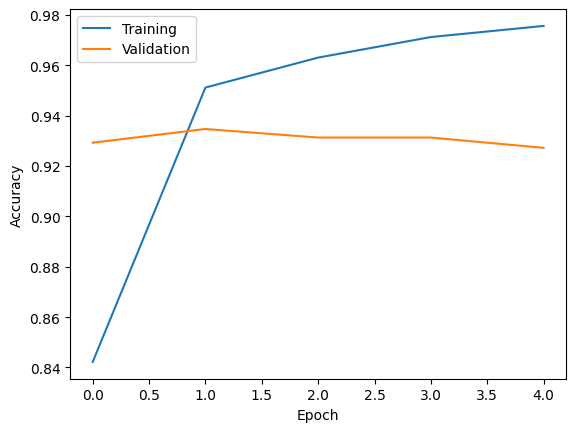

In [272]:
plt.plot(history.history["accuracy"], label="Training")

plt.plot(history.history["val_accuracy"], label="Validation")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

In [259]:
print(history.history["accuracy"])
print(history.history["val_accuracy"])

[0.8422037363052368, 0.9511987566947937, 0.9631015062332153, 0.9712634086608887, 0.975684404373169]
[0.9292997717857361, 0.934738278388977, 0.9313392043113708, 0.9313392043113708, 0.9272603392601013]


Daca incercm sa rulam cu 20 de epoci, observam ca acuratețea pe setul de antrenare crește rapid și atinge 100% după aproximativ 12 epoci, ceea ce indică faptul că modelul a învățat foarte bine datele de antrenare. Acuratețea pe setul de validare se stabilizează în jurul valorii de 95%, fără îmbunătățiri semnificative după aproximativ 10 epoci. Diferența dintre cele două curbe indică apariția unui ușor fenomen de supraînvățare, însă performanța pe datele de validare rămâne ridicată, ceea ce arată că modelul generalizează bine.

Folosind mecanismul EarlyStopping ajungem la concluzia ca pentru 5 epoci obtinem acuratetea cea mai buna pe setul de validare, iar datorită opțiunii restore_best_weights=True pastram automat greutățile corespunzătoare acestei epoci.

Modelul obține o acuratețe foarte ridicată destul de repede pe setul de antrenare, ceea ce este explicabil prin dimensiunea relativ redusă a setului de date și prin faptul că acesta conține caracteristici deja preprocesate și bine separate. Diferența dintre acuratețea pe antrenare și cea pe validare indică un ușor fenomen de supraînvățare, însă performanța pe setul de test rămâne ridicată, ceea ce arată că modelul generalizează corespunzător.

Functia de pierdere (loss)

La finalul fiecărei epoci, Keras calculează media loss-ului peste toate batch-urile; aceasta e valoarea salvată în history.history["loss"].

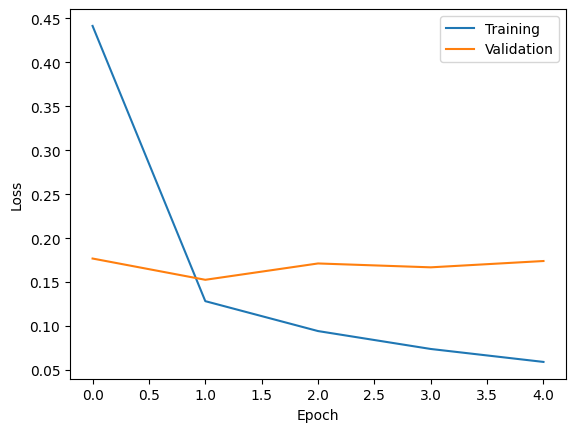

In [260]:
plt.plot(history.history["loss"], label="Training")

plt.plot(history.history["val_loss"], label="Validation")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [261]:
print(history.history["loss"])
print(history.history["val_loss"])

[0.4414575695991516, 0.12831534445285797, 0.09428524225950241, 0.07390466332435608, 0.059176553040742874]
[0.17681710422039032, 0.15261948108673096, 0.17120063304901123, 0.16679419577121735, 0.17398138344287872]


Cea mai bună validation accuracy și cel mai mic validation loss au fost în jurul epocii 5, după aceea performanța pe validare nu s-a mai îmbunătățit.


Cele două metrici sunt de acord- ambele indică epoca 2 ca fiind cel mai bun moment, iar ambele opresc antrenarea după exact 5 epoci.

In [262]:
test_loss, test_accuracy = model.evaluate(
    X_test_ts,
    y_test_ts
)

print("Test accuracy:", test_accuracy)
print("Test loss:", test_loss)

93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8975 - loss: 0.2564
Test accuracy: 0.8975229263305664
Test loss: 0.25639835000038147


Acuratetea modelului este de 89,7%.


In [263]:
predictions = model.predict(X_test_ts)

93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


Vedem clasele prezise

In [264]:
predicted_classes = np.argmax(predictions, axis=1)

In [265]:
predicted_names = [label_model.labels[i] for i in predicted_classes]

In [266]:
predicted_names[:10]

['STANDING',
 'STANDING',
 'STANDING',
 'STANDING',
 'STANDING',
 'STANDING',
 'STANDING',
 'SITTING',
 'SITTING',
 'STANDING']

In [267]:
print(type(confusion_matrix))

<class 'function'>


In [268]:
matrix = confusion_matrix(
    y_test_ts,
    predicted_classes
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=label_model.labels
)


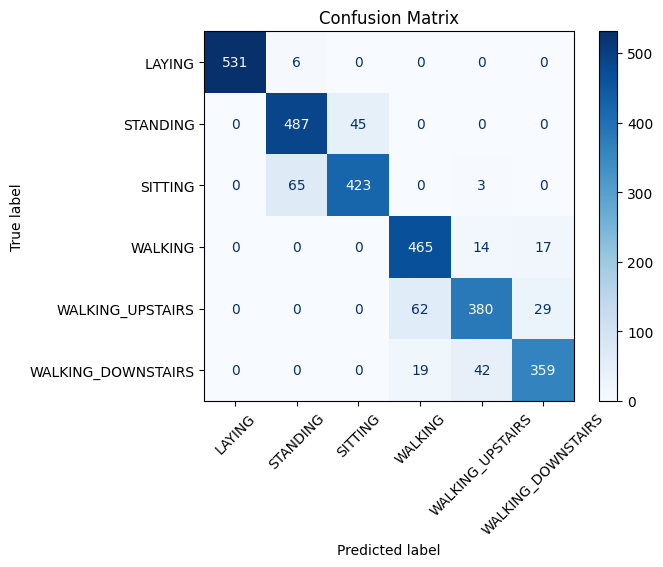

In [269]:
disp.plot(cmap="Blues", xticks_rotation=45)

plt.title("Confusion Matrix")
plt.show()

In [270]:
report = classification_report(
        y_test_ts,
        predicted_classes,
        target_names=label_model.labels
    )

In [271]:
report

'                    precision    recall  f1-score   support\n\n            LAYING       1.00      0.99      0.99       537\n          STANDING       0.87      0.92      0.89       532\n           SITTING       0.90      0.86      0.88       491\n           WALKING       0.85      0.94      0.89       496\n  WALKING_UPSTAIRS       0.87      0.81      0.84       471\nWALKING_DOWNSTAIRS       0.89      0.85      0.87       420\n\n          accuracy                           0.90      2947\n         macro avg       0.90      0.89      0.89      2947\n      weighted avg       0.90      0.90      0.90      2947\n'

#Spark streaming

Cream directorul pe care Spark il va monitoriza.

In [222]:
STREAM_DIR = "/content/stream_input"
STREAM_DATA = "/content/test_parts"
STREAM_PREDICTIONS = "/content/predictions"
STREAM_METRICS = "/content/stream_metrics"

In [223]:
if os.path.exists(STREAM_DIR):
    shutil.rmtree(STREAM_DIR)

if os.path.exists(STREAM_DATA):
    shutil.rmtree(STREAM_DATA)

if os.path.exists(STREAM_PREDICTIONS):
    shutil.rmtree(STREAM_PREDICTIONS)

if os.path.exists(STREAM_METRICS):
    shutil.rmtree(STREAM_METRICS)

os.makedirs(STREAM_DIR)
os.makedirs(STREAM_DATA)
os.makedirs(STREAM_PREDICTIONS)
os.makedirs(STREAM_METRICS)

In [224]:
os.listdir(STREAM_DIR)

[]

Vom transforma temporar datele din format Spark DataFrame in format pandas pentru a imparti setul de date in fisiere de streaming .csv de cate 100 de randuri.

In [225]:
test_remained.count()

2947

In [226]:
test_pd = test_remained.toPandas()

Salvam fisierele de streaming

In [227]:
chunk_size = 100

for i in range(0, len(test_pd), chunk_size):
    chunk = test_pd.iloc[i:i+chunk_size]
    chunk.to_csv(
        f"{STREAM_DATA}/test_part_{i//chunk_size}.csv",
        index=False
    )

Verificam ca fisierele .csv s-au salvat.

In [228]:
files = sorted(os.listdir(STREAM_DATA))
print(files)
print("Număr fișiere:", len(files))

['test_part_0.csv', 'test_part_1.csv', 'test_part_10.csv', 'test_part_11.csv', 'test_part_12.csv', 'test_part_13.csv', 'test_part_14.csv', 'test_part_15.csv', 'test_part_16.csv', 'test_part_17.csv', 'test_part_18.csv', 'test_part_19.csv', 'test_part_2.csv', 'test_part_20.csv', 'test_part_21.csv', 'test_part_22.csv', 'test_part_23.csv', 'test_part_24.csv', 'test_part_25.csv', 'test_part_26.csv', 'test_part_27.csv', 'test_part_28.csv', 'test_part_29.csv', 'test_part_3.csv', 'test_part_4.csv', 'test_part_5.csv', 'test_part_6.csv', 'test_part_7.csv', 'test_part_8.csv', 'test_part_9.csv']
Număr fișiere: 30


In [229]:
part = 0

pd.read_csv(os.path.join(STREAM_DATA, f"test_part_{part}.csv")).head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-max()-Z,tBodyAcc-min()-Z,tBodyAcc-energy()-Y,tBodyAcc-energy()-Z,...,fBodyBodyGyroJerkMag-min(),fBodyBodyGyroJerkMag-maxInds,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)",subject,Activity
0,0.257178,-0.023285,-0.014654,-0.938404,-0.920091,-0.667683,-0.466223,0.789497,-0.998414,-0.934345,...,-0.909829,-1.000000,0.071645,-0.330370,0.006462,0.162920,-0.825886,0.271151,2,STANDING
1,0.286027,-0.013163,-0.119083,-0.975415,-0.967458,-0.944958,-0.806013,0.796706,-0.999646,-0.997720,...,-0.986902,-1.000000,-0.401189,-0.121845,-0.083495,0.017500,-0.434375,0.920593,2,STANDING
2,0.275485,-0.026050,-0.118152,-0.993819,-0.969926,-0.962748,-0.799116,0.822442,-0.999570,-0.998720,...,-0.989609,-0.936508,0.062891,-0.190422,-0.034956,0.202302,0.064103,0.145068,2,STANDING
3,0.270298,-0.032614,-0.117520,-0.994743,-0.973268,-0.967091,-0.799116,0.822442,-0.999330,-0.998933,...,-0.992021,-0.936508,0.116695,-0.344418,-0.017067,0.154438,0.340134,0.296407,2,STANDING
4,0.274833,-0.027848,-0.129527,-0.993852,-0.967445,-0.978295,-0.825894,0.829897,-0.999467,-0.998823,...,-0.992505,-0.936508,-0.121711,-0.534685,-0.002223,-0.040046,0.736715,-0.118545,2,STANDING


Vom folosi datele in format Spark DataFrame dupa ce am aplicat filtrul de corelatie si am eliminat features corelate. Folosim schema acestor date.

In [230]:
schema = test_remained.schema

Cream DataFrame-ul de streaming

In [231]:
stream_df = (
    spark.readStream
         .option("header", True)
         .schema(schema)
         .csv(STREAM_DIR)
)

In [232]:
accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)

Definim functia care proceseaza fiecare batch

In [233]:
def process_batch(batch_df, batch_id):

    print(f"Batch {batch_id}: {batch_df.count()} observatii")

    predictions = pipeline_model_lr.transform(batch_df)

    predictions_named = prediction_converter.transform(predictions)

    print(f"Batch {batch_id}: {predictions.count()} predictii")

    accuracy = accuracy_evaluator.evaluate(predictions_named)
    f1 = f1_evaluator.evaluate(predictions_named)

    predictions_with_batch = predictions_named.withColumn(
    "batch_id",
    F.lit(batch_id) # transformăm în coloană Spark constantă
)

    predictions_with_batch.select(
    "batch_id",
    "Activity",
    "predicted_activity"
).show(5, truncate=False)

    predictions_with_batch.select(
        "batch_id",
        "Activity",
        "predicted_activity"
    ).write \
    .mode("append") \
    .option("header", True) \
    .csv(STREAM_PREDICTIONS)

    metrics_df = spark.createDataFrame(
        [(batch_id, accuracy, f1)],
        ["batch_id", "accuracy", "f1_score"]
    )

    metrics_df.coalesce(1).write \
      .mode("append") \
      .option("header", True) \
      .csv(STREAM_METRICS)

Pornim procesul de streaming

In [234]:
query = (
    stream_df.writeStream
        .foreachBatch(process_batch)
        .start()
)

In [235]:
part = 0

shutil.copy(
    os.path.join(STREAM_DATA, f"test_part_{part}.csv"),
    os.path.join(STREAM_DIR, f"test_part_{part}.csv")
)

'/content/stream_input/test_part_0.csv'

In [236]:
os.listdir(STREAM_DIR)

['test_part_0.csv']

In [237]:
part = 1

shutil.copy(
    os.path.join(STREAM_DATA, f"test_part_{part}.csv"),
    os.path.join(STREAM_DIR, f"test_part_{part}.csv")
)

'/content/stream_input/test_part_1.csv'

In [238]:
os.listdir(STREAM_DIR)

['test_part_0.csv', 'test_part_1.csv']

Am implementat inferența în timp real cu Spark Structured Streaming și am monitorizat performanța modelului pentru fiecare batch procesat folosind Accuracy și F1-score.

In [239]:
predictions = spark.read.option("header", True).csv(STREAM_PREDICTIONS)

predictions.show(20, truncate=False)

+--------+------------------+------------------+
|batch_id|Activity          |predicted_activity|
+--------+------------------+------------------+
|1       |WALKING           |WALKING           |
|1       |WALKING           |WALKING           |
|1       |WALKING           |WALKING           |
|1       |WALKING           |WALKING           |
|1       |WALKING           |WALKING           |
|1       |WALKING           |WALKING           |
|1       |WALKING           |WALKING           |
|1       |WALKING           |WALKING           |
|1       |WALKING           |WALKING           |
|1       |WALKING_DOWNSTAIRS|WALKING_DOWNSTAIRS|
|1       |WALKING_DOWNSTAIRS|WALKING_DOWNSTAIRS|
|1       |WALKING_DOWNSTAIRS|WALKING_DOWNSTAIRS|
|1       |WALKING_DOWNSTAIRS|WALKING_DOWNSTAIRS|
|1       |WALKING_DOWNSTAIRS|WALKING_DOWNSTAIRS|
|1       |WALKING_DOWNSTAIRS|WALKING_DOWNSTAIRS|
|1       |WALKING_DOWNSTAIRS|WALKING_DOWNSTAIRS|
|1       |WALKING_DOWNSTAIRS|WALKING_DOWNSTAIRS|
|1       |WALKING_DO

In [240]:
metrics = spark.read.option("header", True).csv(STREAM_METRICS)

metrics.show()

+--------+--------+------------------+
|batch_id|accuracy|          f1_score|
+--------+--------+------------------+
|       0|    0.91|0.9090769230769231|
|       1|    0.93|0.9297444504117436|
+--------+--------+------------------+



In [241]:
query.stop()

In [215]:
for s in spark.streams.active:
    s.stop()

In [216]:
len(spark.streams.active)

0

In [242]:
query.status

{'message': 'Stopped', 'isDataAvailable': False, 'isTriggerActive': False}